# Human vs. AI Text: Baseline Experiment

Labels are 0 = Human and 1 = AI, the experiment uses a stratified validation set of 2,000 passages and random seed 42.

**Run order:** Select the project `.venv` kernel and run cells from top to bottom. The notebook finds `data/` from either the project root or `notebooks/` and all generated files go to the project’s `outputs/` folder.

## Contents

1. [Environment and configuration](#1-environment-and-configuration)
2. [Load the datasets](#2-load-the-datasets)
3. [Explore data quality and distributions](#3-explore-data-quality-and-distributions)
4. [Create the training and validation split](#4-create-the-training-and-validation-split)
5. [Define the baseline model](#5-define-the-baseline-model)
6. [Train the model](#6-train-the-model)
7. [Evaluate on the validation set](#7-evaluate-on-the-validation-set)
8. [Save results and artifacts](#8-save-results-and-artifacts)
9. [Kaggle Submission](#9-kaggle-submission)

## 1. Environment and configuration

### 1.1 Install dependencies

Run this cell when setting up the notebook environment. If packages are updated, restart the kernel before continuing.

In [32]:
%pip install pandas numpy matplotlib scikit-learn joblib

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/sanskritimalakar/Kaggle-Competition-AML/.venv/lib/python3.14/site-packages/pip/__main__.py", line 8, in <module>
    if sys.path[0] in ("", os.getcwd()):
                           ~~~~~~~~~^^
FileNotFoundError: [Errno 2] No such file or directory
Note: you may need to restart the kernel to use updated packages.


### 1.2 Import libraries and configure paths

Set the random seed, locate the project’s data folder, and create the output directory.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42

# Locate the project whether Jupyter starts in the root or notebooks/.
PROJECT_ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "train.csv").is_file()
     and (folder / "data" / "test.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/train.csv and data/test.csv. "
        "Start Jupyter from the project folder or its notebooks folder."
    )

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

FileNotFoundError: [Errno 2] No such file or directory

## 2. Load the datasets

Read `data/train.csv` (text and labels) and `data/test.csv` (text without labels). Preview both tables to confirm their columns and row counts. 

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

DATA_DIR = next(
    (folder / "data" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "train.csv").is_file()
     and (folder / "data" / "test.csv").is_file()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        f"Could not find data/train.csv and data/test.csv from {Path.cwd()}. "
        "Open this notebook from the Kaggle-Competition-AML project."
    )

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Training shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())
display(test.head())

Training shape: (10000, 3)
Test shape: (3000, 2)


,id,text,label
0,1,Cipriani S.A. is an Italian hotel and leisure ...,0
1,2,My Grandpa passed away 3 years ago from cancer...,0
2,3,"""Petit Beurre -- Butter Cookies\n\n1 cup (2 st...",1
3,4,"In an unprecedented move, a dedicated gamer ha...",1
4,5,Chile's copper industry has registered record ...,0


,id,text
0,13001,Ingredients:\n\n1 tablespoon olive oil\n\n1 on...
1,13002,Help me to salt help me to sorrow\nThe choices...
2,13003,"In the enchanting world of Stone Run Forest, a..."
3,13004,The Display Handicap was an American long dist...
4,13005,"The story takes place in 1959, with Cay, who n..."


## 3. Explore data quality and distributions

### 3.1 Schema, missing values, and duplicates

Inspect training column types, missing values, label counts, duplicate IDs, and duplicate training passages.

In [ ]:
# Inspect the training schema.
train.info()

# Count missing values in each training column.
print("\nMissing values:")
print(train.isnull().sum())

# Count examples for each label.
print("\nLabel distribution:")
print(train["label"].value_counts())

# Check ID uniqueness in each dataset.
print("\nDuplicate training IDs:", train["id"].duplicated().sum())
print("Duplicate test IDs:", test["id"].duplicated().sum())

# Count repeated training passages.
print("Duplicate training passages:", train["text"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      10000 non-null  int64
 1   text    10000 non-null  str  
 2   label   10000 non-null  int64
dtypes: int64(2), str(1)
memory usage: 234.5 KB

Missing values:
id       0
text     0
label    0
dtype: int64

Label distribution:
label
0    5000
1    5000
Name: count, dtype: int64

Duplicate training IDs: 0
Duplicate test IDs: 0
Duplicate training passages: 0


### 3.2 Class balance

Compare the number of human and AI passages in the labeled dataset.

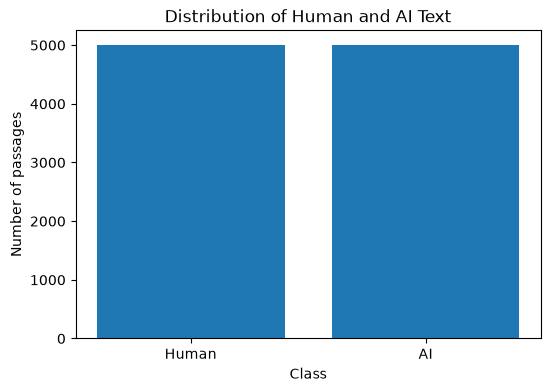

In [ ]:
label_counts = train["label"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Human", "AI"],
    label_counts.values
)

plt.xlabel("Class")
plt.ylabel("Number of passages")
plt.title("Distribution of Human and AI Text")

plt.show()

### 3.3 Text length summary

Count whitespace-separated words per passage and summarize lengths overall and by label.

In [ ]:
train["word_count"] = train["text"].fillna("").str.split().str.len()

print("Overall text length statistics:")
display(train["word_count"].describe())

print("\nText length statistics by class:")
display(train.groupby("label")["word_count"].describe())

Overall text length statistics:


count    10000.000000
mean       208.708700
std         62.685657
min         75.000000
25%        160.000000
50%        206.000000
75%        256.000000
max        350.000000
Name: word_count, dtype: float64


Text length statistics by class:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,5000.0,209.0452,55.065056,75.0,166.0,204.0,250.0,350.0
1,5000.0,208.3722,69.479366,75.0,151.0,209.0,262.0,350.0


### 3.4 Text length distribution by class

Compare passage lengths for human and AI text using overlaid histograms.

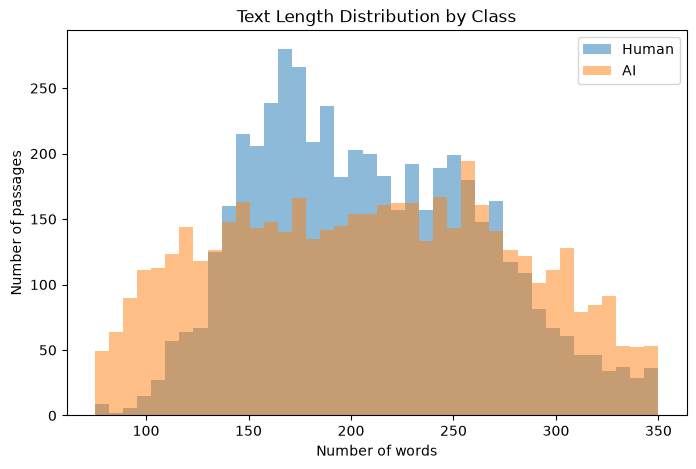

In [ ]:
plt.figure(figsize=(8, 5))

for label, name in [(0, "Human"), (1, "AI")]:
    subset = train[train["label"] == label]

    plt.hist(
        subset["word_count"],
        bins=40,
        alpha=0.5,
        label=name
    )

plt.xlabel("Number of words")
plt.ylabel("Number of passages")
plt.title("Text Length Distribution by Class")
plt.legend()
plt.show()

## 4. Create the training and validation split

### 4.1 Reproducible stratified split

Reserve 2,000 passages for validation and use the remaining passages for training. Stratification preserves class proportions, and `RANDOM_STATE` makes the split reproducible. Replace missing text with empty strings before modeling.

In [ ]:
train_indices, val_indices = train_test_split(
    np.arange(len(train)),
    test_size=2000,
    random_state=RANDOM_STATE,
    stratify=train["label"]
)

train_split = train.iloc[train_indices].copy()
val_split = train.iloc[val_indices].copy()

X_train = train_split["text"].fillna("")
y_train = train_split["label"]

X_val = val_split["text"].fillna("")
y_val = val_split["label"]

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nValidation label distribution:")
print(y_val.value_counts())

Training examples: 8000
Validation examples: 2000

Training label distribution:
label
0    4000
1    4000
Name: count, dtype: int64

Validation label distribution:
label
0    1000
1    1000
Name: count, dtype: int64


### 4.2 Check passage overlap

Count identical passages shared across the split after trimming surrounding whitespace.

In [ ]:
# check for identical text across training and validation.
train_texts = set(X_train.str.strip())
val_texts = set(X_val.str.strip())

overlap = train_texts.intersection(val_texts)

print("Overlapping passages:", len(overlap))

Overlapping passages: 0


### 4.3 Save split IDs

Save `train_ids.csv` and `validation_ids.csv` so later experiments can reuse the same examples.

In [ ]:
train_split[["id"]].to_csv(
    OUTPUT_DIR / "train_ids.csv",
    index=False
)

val_split[["id"]].to_csv(
    OUTPUT_DIR / "validation_ids.csv",
    index=False
)

print("Training and validation IDs saved.")

Training and validation IDs saved.


## 5. Define the baseline model

The pipeline converts text to TF-IDF features, then fits a Logistic Regression classifier. TF-IDF uses unigrams and bigrams, keeps terms appearing in at least two training passages, and limits the vocabulary to 50,000 features.

Fitting both steps inside one pipeline ensures the vocabulary and TF-IDF weights are learned from the training split.

In [ ]:
# feature extraction and classification pipeline.
baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

print(baseline_model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=50000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


## 6. Train the model

Fit the pipeline on the training split and record the elapsed training time.

In [ ]:
import time

# Time pipeline fitting.
start_time = time.perf_counter()

# Fit on training text and labels.
baseline_model.fit(X_train, y_train)

train_time = time.perf_counter() - start_time

print(f"Training completed in {train_time:.2f} seconds")

Training completed in 2.36 seconds


## 7. Evaluate on the validation set

### 7.1 Predict AI probabilities

Calculate probabilities for label 1 (AI). Convert validation probabilities to class predictions using a threshold of **0.5**.

In [ ]:
# predict AI probabilities for training and validation.

train_probs = baseline_model.predict_proba(X_train)[:, 1]
val_probs = baseline_model.predict_proba(X_val)[:, 1]

# convert validation probabilities to binary predictions.
val_preds = (val_probs >= 0.5).astype(int)

print("First 10 validation probabilities:")
print(val_probs[:10])

First 10 validation probabilities:
[0.40318976 0.66724001 0.25714237 0.69594505 0.15613093 0.4305091
 0.1931933  0.62692987 0.33404499 0.81448129]


### 7.2 AUROC, accuracy, and training–validation gap

AUROC measures how well the model ranks AI text above human text across thresholds. 

In [ ]:
# Summarize predictive performance and training time.

train_auc = roc_auc_score(y_train, train_probs)
val_auc = roc_auc_score(y_val, val_probs)
val_accuracy = accuracy_score(y_val, val_preds)

print(f"Training AUROC: {train_auc:.4f}")
print(f"Validation AUROC: {val_auc:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"AUROC Gap: {train_auc - val_auc:.4f}")
print(f"Training Time: {train_time:.2f} seconds")

Training AUROC: 0.9932
Validation AUROC: 0.9361
Validation Accuracy: 0.8670
AUROC Gap: 0.0571
Training Time: 2.36 seconds


### 7.3 Validation ROC curve

Visualize the true positive and false positive rates as the classification threshold varies.

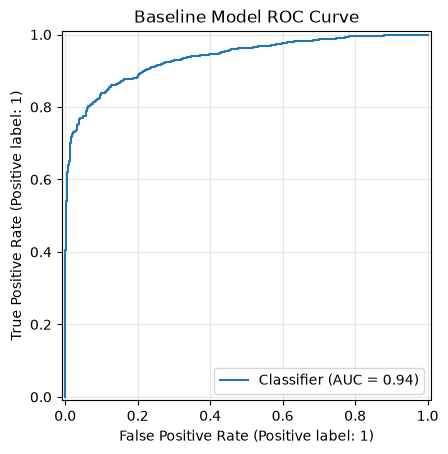

In [ ]:
# Plot the validation ROC curve.
RocCurveDisplay.from_predictions(
    y_val,
    val_probs
)

plt.title("Baseline Model ROC Curve")
plt.grid(alpha=0.3)
plt.show()

### 7.4 Validation confusion matrix

Compare true and predicted classes at the 0.5 threshold to inspect classification errors.

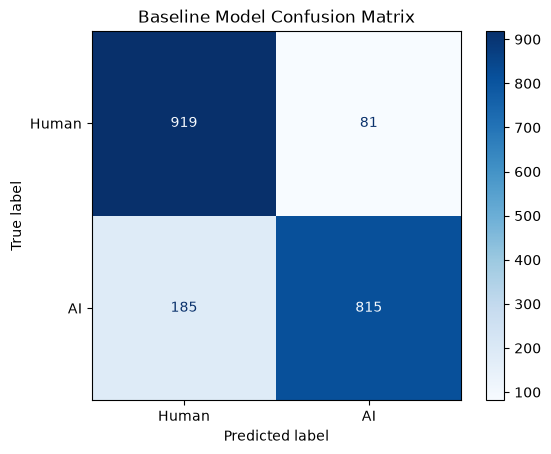

In [ ]:
# plot validation classification counts.
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_preds,
    display_labels=["Human", "AI"],
    cmap="Blues"
)

plt.title("Baseline Model Confusion Matrix")
plt.show()

### 7.5 Precision, recall, and F1 by class

Review performance for human and AI passages separately, along with the number of examples in each class.

In [ ]:
# report validation metrics for each class.
print(classification_report(
    y_val,
    val_preds,
    target_names=["Human", "AI"]
))

              precision    recall  f1-score   support

       Human       0.83      0.92      0.87      1000
          AI       0.91      0.81      0.86      1000

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



## 8. Save results and artifacts

All files below are written to the project’s `outputs/` directory. Rerunning these cells replaces files with the same names.

| File | Contents |
| --- | --- |
| `train_ids.csv` | Training split IDs, saved in Section 4 |
| `validation_ids.csv` | Validation split IDs, saved in Section 4 |
| `baseline_results.csv` | AUROC, accuracy, generalization gap, and training time |
| `baseline_validation_predictions.csv` | Validation IDs, text, true labels, and predictions |
| `baseline_model.joblib` | Fitted TF-IDF and Logistic Regression pipeline |

### 8.1 Save experiment metrics

In [ ]:
baseline_results = pd.DataFrame([{
    "model": "TF-IDF + Logistic Regression",
    "train_auc": train_auc,
    "val_auc": val_auc,
    "auc_gap": train_auc - val_auc,
    "val_accuracy": val_accuracy,
    "training_time_seconds": train_time
}])

baseline_results.to_csv(
    OUTPUT_DIR / "baseline_results.csv",
    index=False
)

display(baseline_results)

,model,train_auc,val_auc,auc_gap,val_accuracy,training_time_seconds
0,TF-IDF + Logistic Regression,0.993194,0.936066,0.057128,0.867,2.363501


### 8.2 Save validation predictions

Keep passage-level predictions for error analysis and comparisons with future models.

In [ ]:
# save validation predictions with their original IDs and labels.
validation_predictions = val_split[["id", "text", "label"]].copy()

validation_predictions["predicted_probability"] = val_probs
validation_predictions["predicted_label"] = val_preds

validation_predictions.to_csv(
    OUTPUT_DIR / "baseline_validation_predictions.csv",
    index=False
)

display(validation_predictions.head())

,id,text,label,predicted_probability,predicted_label
5864,5865,"Usually, Neural Networks models are trained wi...",0,0.403190,0
1773,1774,Ingredients\n\n4 sweet potatoes\n\n1/2 cup (10...,1,0.667240,1
3335,3336,"Elissa Panush Benedek (born September 28, 1936...",0,0.257142,0
9081,9082,HMS Shannon was a 18-gun sloop of the Royal Na...,1,0.695945,1
6969,6970,I don't know - I'm way too old for a middle li...,0,0.156131,0


### 8.3 Save the trained pipeline

Persist the fitted vectorizer and classifier together so they can be loaded for inference.

In [ ]:
# save the fitted baseline pipeline.
joblib.dump(
    baseline_model,
    OUTPUT_DIR / "baseline_model.joblib"
)

print("Baseline model saved.")

Baseline model saved.


## 9. Kaggle Submission


Retrain the TF-IDF + Logistic Regression model using all 10,000 labeled training examples. We then use the trained model to predict the probability that each passage in the test dataset was generated by AI.

The predictions are saved in a CSV file for submission to Kaggle.

In [ ]:
from sklearn.base import clone

final_baseline_model = clone(baseline_model)

X_full = train["text"].fillna("")
y_full = train["label"]

start_time = time.perf_counter()

final_baseline_model.fit(X_full, y_full)

full_train_time = time.perf_counter() - start_time

print("Training examples:", len(X_full))
print(f"Training time: {full_train_time:.2f} seconds")

Training examples: 10000
Training time: 2.76 seconds


In [ ]:
# get test passages
X_test = test["text"].fillna("")

# predict probability of AI-generated text
test_probs = final_baseline_model.predict_proba(X_test)[:, 1]

print("Number of test examples:", len(X_test))
print("Number of predictions:", len(test_probs))

print("\nFirst 10 predicted probabilities:")
print(test_probs[:10])

Number of test examples: 3000
Number of predictions: 3000

First 10 predicted probabilities:
[0.83975573 0.23782059 0.56114225 0.17021194 0.7644736  0.27980026
 0.23971185 0.47431569 0.29619209 0.41455015]


In [ ]:
# create submission dataframe
submission = pd.DataFrame({
    "id": test["id"],
    "label": test_probs
})

# save submission file
submission_path = OUTPUT_DIR / "submission_baseline.csv"

submission.to_csv(submission_path, index=False)

print("Submission saved to:", submission_path)

display(submission.head())

Submission saved to: /Users/sanskritimalakar/Kaggle-Competition-AML/outputs/submission_baseline.csv


,id,label
0,13001,0.839756
1,13002,0.237821
2,13003,0.561142
3,13004,0.170212
4,13005,0.764474
